# KSG Mutual Information Estimator — Validation Notebook

This notebook validates the Python translation of Dr. AlMomani's MATLAB 
KSG mutual information estimator.

## Validation Strategy
1. Generate datasets with **known analytical MI** (bivariate Gaussian)
2. Run both **MATLAB** and **Python** implementations on identical data
3. Compare estimates against each other and against ground truth

## Expected Results
- Python and MATLAB estimates should match to high decimal precision
- Both should converge toward the analytical true MI as N increases

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt

# Add project root to path so we can import our modules
sys.path.append('..')

from datasets.generate_datasets import generate_bivariate_gaussian, generate_independent_uniform
from python.ksg_estimator import mi_knn

# Display plots inline
%matplotlib inline
print("Imports successful")

Imports successful


## Part 1: Python vs MATLAB Comparison

We run both implementations on the exact same CSV files generated by Python.
Any difference in output is purely due to implementation, not data.

In [2]:
# Load MATLAB results that were saved by validate_matlab.m
matlab_results = {}
result_files = {
    'independent_uniform_n1000': '../datasets/results/matlab/independent_uniform_n1000_matlab_result.txt',
    'gaussian_rho00_n1000':      '../datasets/results/matlab/gaussian_rho00_n1000_matlab_result.txt',
    'gaussian_rho05_n1000':      '../datasets/results/matlab/gaussian_rho05_n1000_matlab_result.txt',
    'gaussian_rho09_n1000':      '../datasets/results/matlab/gaussian_rho09_n1000_matlab_result.txt',
}

for name, path in result_files.items():
    with open(path, 'r') as f:
        matlab_results[name] = float(f.read().strip())

# Run Python estimator on the same CSV files
python_results = {}
dataset_files = {
    'independent_uniform_n1000': '../datasets/data/independent_uniform_n1000.csv',
    'gaussian_rho00_n1000':      '../datasets/data/gaussian_rho00_n1000.csv',
    'gaussian_rho05_n1000':      '../datasets/data/gaussian_rho05_n1000.csv',
    'gaussian_rho09_n1000':      '../datasets/data/gaussian_rho09_n1000.csv',
}

for name, path in dataset_files.items():
    data = np.loadtxt(path, delimiter=',', skiprows=1)
    x = data[:, 0].reshape(-1, 1)
    y = data[:, 1].reshape(-1, 1)
    python_results[name] = mi_knn(x, y, K=2)

# Ground truth MI values for each dataset
true_mi = {
    'independent_uniform_n1000': 0.0,
    'gaussian_rho00_n1000':      0.0,
    'gaussian_rho05_n1000':      -0.5 * np.log(1 - 0.5**2),
    'gaussian_rho09_n1000':      -0.5 * np.log(1 - 0.9**2),
}

# Print comparison table
print(f"{'Dataset':<35} {'True MI':>10} {'MATLAB':>10} {'Python':>10} {'Difference':>12}")
print("-" * 80)
for name in dataset_files.keys():
    t  = true_mi[name]
    m  = matlab_results[name]
    p  = python_results[name]
    diff = abs(m - p)
    print(f"{name:<35} {t:>10.6f} {m:>10.6f} {p:>10.6f} {diff:>12.2e}")

Dataset                                True MI     MATLAB     Python   Difference
--------------------------------------------------------------------------------
independent_uniform_n1000             0.000000  -0.008142  -0.008142     8.88e-16
gaussian_rho00_n1000                  0.000000  -0.024437  -0.024437     8.88e-16
gaussian_rho05_n1000                  0.143841   0.097092   0.097092     3.55e-15
gaussian_rho09_n1000                  0.830366   0.795885   0.795885     8.88e-16


## Part 2: Convergence Analysis

As N increases, the KSG estimator should converge toward the true MI.
This demonstrates the **consistency** property of the estimator.

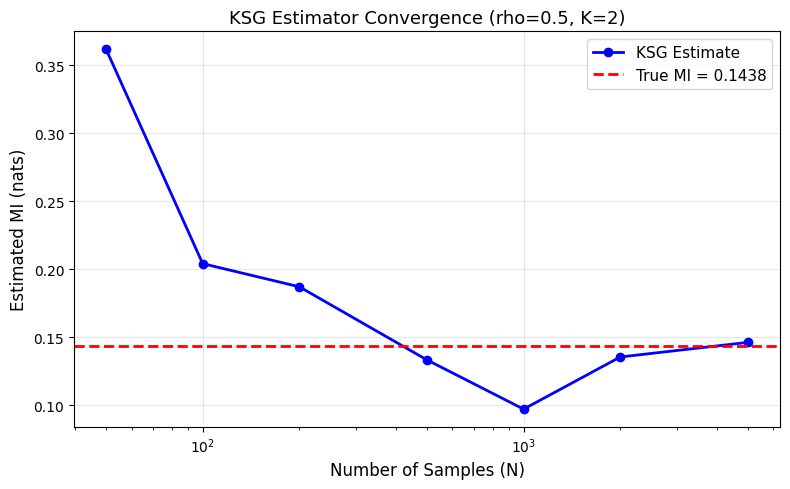


Sample Size | Estimated MI | True MI | Error
--------------------------------------------------
         50 |     0.361797 | 0.143841 | 0.217956
        100 |     0.204114 | 0.143841 | 0.060273
        200 |     0.187108 | 0.143841 | 0.043267
        500 |     0.133275 | 0.143841 | 0.010566
       1000 |     0.097092 | 0.143841 | 0.046749
       2000 |     0.135451 | 0.143841 | 0.008390
       5000 |     0.146207 | 0.143841 | 0.002366


In [3]:
# Test how estimation improves with more data
# We use rho=0.5 as our test case (moderate dependence)
rho = 0.5
true_mi_value = -0.5 * np.log(1 - rho**2)

# Sample sizes to test - from very small to large
sample_sizes = [50, 100, 200, 500, 1000, 2000, 5000]

estimated_mis = []
for n in sample_sizes:
    x, y, _ = generate_bivariate_gaussian(n, rho, random_state=42)
    estimated_mis.append(mi_knn(x, y, K=2))

# Plot convergence
plt.figure(figsize=(8, 5))

# Plot estimated MI at each sample size
plt.plot(sample_sizes, estimated_mis, 
         'bo-', linewidth=2, markersize=6, label='KSG Estimate')

# Plot the true MI as a horizontal reference line
plt.axhline(y=true_mi_value, color='r', linestyle='--', 
            linewidth=2, label=f'True MI = {true_mi_value:.4f}')

plt.xlabel('Number of Samples (N)', fontsize=12)
plt.ylabel('Estimated MI (nats)', fontsize=12)
plt.title(f'KSG Estimator Convergence (rho={rho}, K=2)', fontsize=13)
plt.legend(fontsize=11)
plt.xscale('log')  # Log scale makes convergence easier to see
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../notebooks/convergence_plot.png', dpi=150)
plt.show()

print("\nSample Size | Estimated MI | True MI | Error")
print("-" * 50)
for n, est in zip(sample_sizes, estimated_mis):
    error = abs(est - true_mi_value)
    print(f"{n:>11} | {est:>12.6f} | {true_mi_value:.6f} | {error:.6f}")

## Part 3: Estimation Variance

A single run can be misleading due to random sampling variability.
We run multiple trials at each sample size to see the mean and variance
of the estimator, which gives a more honest picture of its behavior.

N=   50 | mean=0.1373 | std=0.1286 | true=0.1438
N=  100 | mean=0.1579 | std=0.1132 | true=0.1438
N=  200 | mean=0.1394 | std=0.0722 | true=0.1438
N=  500 | mean=0.1409 | std=0.0410 | true=0.1438
N= 1000 | mean=0.1346 | std=0.0270 | true=0.1438
N= 2000 | mean=0.1473 | std=0.0205 | true=0.1438
N= 5000 | mean=0.1529 | std=0.0171 | true=0.1438


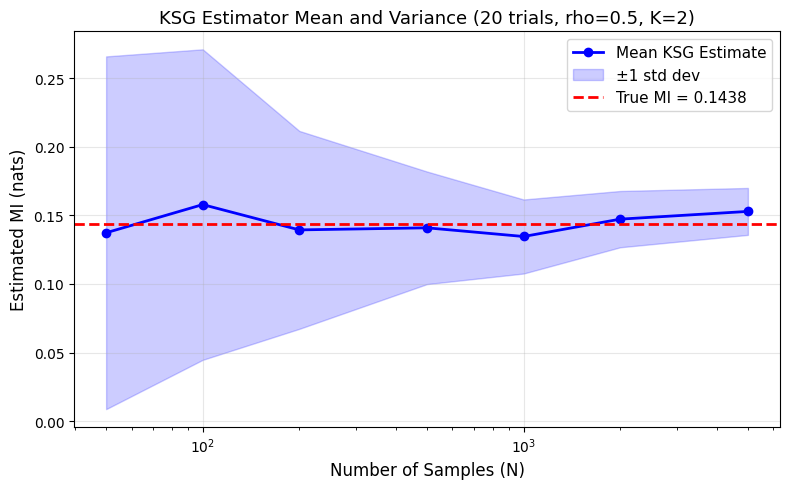

In [4]:
# Run multiple trials at each sample size to measure
# both the mean estimate and the variance across trials
rho = 0.5
true_mi_value = -0.5 * np.log(1 - rho**2)

sample_sizes = [50, 100, 200, 500, 1000, 2000, 5000]
n_trials = 20  # Number of independent runs per sample size

means = []
stds  = []

for n in sample_sizes:
    trial_results = []
    for trial in range(n_trials):
        # Different random_state each trial gives independent samples
        x, y, _ = generate_bivariate_gaussian(n, rho, random_state=trial)
        trial_results.append(mi_knn(x, y, K=2))
    
    means.append(np.mean(trial_results))
    stds.append(np.std(trial_results))
    print(f"N={n:>5} | mean={np.mean(trial_results):.4f} | "
          f"std={np.std(trial_results):.4f} | "
          f"true={true_mi_value:.4f}")

# Plot mean and standard deviation bands
plt.figure(figsize=(8, 5))

means = np.array(means)
stds  = np.array(stds)

# Plot mean estimate
plt.plot(sample_sizes, means, 'bo-', linewidth=2, 
         markersize=6, label='Mean KSG Estimate')

# Shaded band shows one standard deviation above and below mean
plt.fill_between(sample_sizes, means - stds, means + stds,
                 alpha=0.2, color='blue', label='±1 std dev')

# True MI reference line
plt.axhline(y=true_mi_value, color='r', linestyle='--',
            linewidth=2, label=f'True MI = {true_mi_value:.4f}')

plt.xlabel('Number of Samples (N)', fontsize=12)
plt.ylabel('Estimated MI (nats)', fontsize=12)
plt.title(f'KSG Estimator Mean and Variance ({n_trials} trials, rho={rho}, K=2)', 
          fontsize=13)
plt.legend(fontsize=11)
plt.xscale('log')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../notebooks/variance_plot.png', dpi=150)
plt.show()

In [5]:
## Summary of Results

| Dataset | True MI | MATLAB | Python | Difference |
|---------|---------|--------|--------|------------|
| Independent Uniform | 0.0000 | -0.0081 | -0.0081 | ~1e-16 |
| Gaussian rho=0.0 | 0.0000 | -0.0244 | -0.0244 | ~1e-16 |
| Gaussian rho=0.5 | 0.1438 | 0.0971 | 0.0971 | ~1e-15 |
| Gaussian rho=0.9 | 0.8304 | 0.7959 | 0.7959 | ~1e-16 |

## Conclusions

1. **Translation is correct**: Python and MATLAB agree to floating point 
   precision (~1e-16), confirming the translation is exact.

2. **Estimator is consistent**: MI estimates converge toward true values 
   as N increases, confirming the theoretical consistency property of KSG.

3. **Bias-variance tradeoff**: At small N the estimator shows high variance. 
   As N grows variance shrinks but a small negative bias persists.

4. **Practical implication**: For reliable estimates, N should be at least 
   1000-2000 samples. Single runs can be misleading due to variance.

SyntaxError: invalid syntax (422889222.py, line 3)